In [1]:
#读取清洗后的数据
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve)

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

train = pd.read_csv("processed/train_clean.csv")
test = pd.read_csv("processed/test_clean.csv")

non_features = ["fail", "timestamp", "grpA_missing"]   # 基线不使用候选特征 grpA_missing
X_train = train.drop(columns=non_features)
X_test = test.drop(columns=non_features)
y_train, y_test = train["fail"], test["fail"]

print("训练集:", X_train.shape, "不良率 {:.2%}".format(y_train.mean()))
print("测试集:", X_test.shape, "不良率 {:.2%}".format(y_test.mean()))

训练集: (1096, 268) 不良率 7.12%
测试集: (471, 268) 不良率 5.52%


In [2]:
#训练3个模型并评估
models = {
    "Dummy（全部预测合格）": DummyClassifier(strategy="most_frequent"),
    "逻辑回归": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", C=0.1, max_iter=5000)),
    "随机森林": RandomForestClassifier(
        n_estimators=500, class_weight="balanced_subsample",
        min_samples_leaf=3, random_state=42, n_jobs=-1),
}

rows, probas = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]   # 预测为"不良"的概率
    pred = (proba >= 0.5).astype(int)           # 默认阈值 0.5
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    probas[name] = proba
    rows.append({
        "模型": name,
        "准确率": (tp + tn) / len(y_test),
        "召回率": recall_score(y_test, pred, zero_division=0),
        "精确率": precision_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "抓到不良": tp, "漏掉不良": fn, "误报": fp,
    })

results = pd.DataFrame(rows).round(3)
results

,模型,准确率,召回率,精确率,F1,PR-AUC,ROC-AUC,抓到不良,漏掉不良,误报
0,Dummy（全部预测合格）,0.945,0.0,0.0,0.0,0.055,0.500,0,26,0
1,逻辑回归,0.907,0.0,0.0,0.0,0.070,0.601,0,26,18
2,随机森林,0.945,0.0,0.0,0.0,0.070,0.590,0,26,0


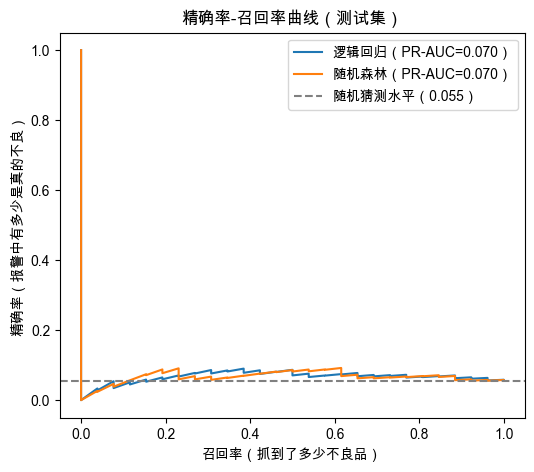

In [3]:
#PR曲线
plt.figure(figsize=(6, 5))
for name in ["逻辑回归", "随机森林"]:
    precision, recall, _ = precision_recall_curve(y_test, probas[name])
    plt.plot(recall, precision, label=f"{name}（PR-AUC={results.set_index('模型').loc[name, 'PR-AUC']:.3f}）")

plt.axhline(y_test.mean(), color="gray", linestyle="--",
            label=f"随机猜测水平（{y_test.mean():.3f}）")
plt.xlabel("召回率（抓到了多少不良品）")
plt.ylabel("精确率（报警中有多少是真的不良）")
plt.title("精确率-召回率曲线（测试集）")
plt.legend()
plt.show()

In [4]:
#时间序列交叉验证+特征数量对比
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import TimeSeriesSplit
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold

tscv = TimeSeriesSplit(n_splits=4)

def make_model(kind, k):
    selector = [VarianceThreshold(), SelectKBest(f_classif, k=k)]
    if kind == "逻辑回归":
        return make_pipeline(StandardScaler(), *selector,
                             LogisticRegression(class_weight="balanced", C=0.1, max_iter=5000))
    return make_pipeline(*selector,
                         RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                min_samples_leaf=3, random_state=42, n_jobs=-1))

rows = []
for kind in ["逻辑回归", "随机森林"]:
    for k in [10, 20, 50, 100, "all"]:
        scores = []
        for tr, va in tscv.split(X_train):
            if y_train.iloc[va].sum() == 0:
                continue
            m = make_model(kind, k).fit(X_train.iloc[tr], y_train.iloc[tr])
            scores.append(average_precision_score(y_train.iloc[va],
                                                  m.predict_proba(X_train.iloc[va])[:, 1]))
        rows.append({"模型": kind, "特征数k": k,
                     "验证PR-AUC均值": round(np.mean(scores), 3),
                     "各折结果": np.round(scores, 3)})

cv_results = pd.DataFrame(rows).sort_values("验证PR-AUC均值", ascending=False).reset_index(drop=True)
cv_results

,模型,特征数k,验证PR-AUC均值,各折结果
0,随机森林,100,0.253,"[0.118, 0.262, 0.222, 0.41]"
1,随机森林,20,0.250,"[0.123, 0.32, 0.198, 0.357]"
2,随机森林,all,0.174,"[0.119, 0.177, 0.193, 0.205]"
3,随机森林,10,0.162,"[0.147, 0.205, 0.202, 0.094]"
4,随机森林,50,0.137,"[0.129, 0.177, 0.059, 0.184]"
5,逻辑回归,50,0.095,"[0.111, 0.197, 0.045, 0.029]"
6,逻辑回归,all,0.093,"[0.113, 0.164, 0.063, 0.032]"
7,逻辑回归,20,0.092,"[0.107, 0.205, 0.03, 0.026]"
8,逻辑回归,100,0.092,"[0.13, 0.175, 0.04, 0.022]"
9,逻辑回归,10,0.090,"[0.117, 0.154, 0.041, 0.049]"


In [5]:
#用验证集预测结果选阈值
best_kind, best_k = cv_results.loc[0, "模型"], cv_results.loc[0, "特征数k"]
print(f"验证表现最好的组合：{best_kind}，特征数 k = {best_k}")

# 收集每一折验证数据上的预测概率（模型训练时没见过这些数据）
oof_proba = np.full(len(X_train), np.nan)
for tr, va in tscv.split(X_train):
    m = make_model(best_kind, best_k).fit(X_train.iloc[tr], y_train.iloc[tr])
    oof_proba[va] = m.predict_proba(X_train.iloc[va])[:, 1]

mask = ~np.isnan(oof_proba)
p, r, t = precision_recall_curve(y_train[mask], oof_proba[mask])
f1 = 2 * p * r / (p + r + 1e-9)
best_t = t[np.argmax(f1[:-1])]
print(f"在验证数据上 F1 最高的阈值：{best_t:.3f}")

验证表现最好的组合：随机森林，特征数 k = 100
在验证数据上 F1 最高的阈值：0.203


In [6]:
#用全部训练集重新训练，在测试集上最终评估
final_model = make_model(best_kind, best_k).fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]

for name, thr in [("默认阈值 0.5", 0.5), (f"验证选出的阈值 {best_t:.3f}", best_t)]:
    pred = (test_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    print(f"\n【{name}】")
    print(f"抓到不良 {tp} / {tp + fn}，误报 {fp}，"
          f"召回率 {tp / (tp + fn):.2%}，精确率 {tp / max(tp + fp, 1):.2%}")

print(f"\n测试集 PR-AUC: {average_precision_score(y_test, test_proba):.3f}"
      f"（基线 0.070，随机水平 {y_test.mean():.3f}）")


【默认阈值 0.5】
抓到不良 0 / 26，误报 0，召回率 0.00%，精确率 0.00%

【验证选出的阈值 0.203】
抓到不良 0 / 26，误报 3，召回率 0.00%，精确率 0.00%

测试集 PR-AUC: 0.081（基线 0.070，随机水平 0.055）


In [7]:
#诊断+按检测预算评估
from sklearn.metrics import roc_auc_score

print(f"测试集 PR-AUC: {average_precision_score(y_test, test_proba):.3f}（随机水平 {y_test.mean():.3f}）")
print(f"测试集 ROC-AUC: {roc_auc_score(y_test, test_proba):.3f}（随机水平 0.5）")

# 1. 概率分布是否发生了漂移？
val_fail_proba = oof_proba[mask][y_train[mask].values == 1]
print(f"\n验证数据中，不良品预测概率的中位数: {np.median(val_fail_proba):.3f}")
print(f"测试集中，不良品预测概率的中位数: {np.median(test_proba[y_test.values == 1]):.3f}")
print(f"测试集所有产品中最高的预测概率: {test_proba.max():.3f}（阈值 {best_t:.3f}）")

# 2. 按检测预算：只检查风险最高的前 X%
print("\n【按检测预算评估】")
order = np.argsort(test_proba)[::-1]
n_fail = y_test.sum()
for pct in [0.05, 0.10, 0.20]:
    n = int(len(test_proba) * pct)
    caught = y_test.iloc[order[:n]].sum()
    print(f"检查风险最高的 {pct:.0%}（{n} 个）：抓到不良 {caught}/{n_fail}，"
          f"随机抽检同样数量预期抓到 {n_fail * pct:.1f} 个")

测试集 PR-AUC: 0.081（随机水平 0.055）
测试集 ROC-AUC: 0.632（随机水平 0.5）

验证数据中，不良品预测概率的中位数: 0.161
测试集中，不良品预测概率的中位数: 0.074
测试集所有产品中最高的预测概率: 0.249（阈值 0.203）

【按检测预算评估】
检查风险最高的 5%（23 个）：抓到不良 1/26，随机抽检同样数量预期抓到 1.3 个
检查风险最高的 10%（47 个）：抓到不良 3/26，随机抽检同样数量预期抓到 2.6 个
检查风险最高的 20%（94 个）：抓到不良 9/26，随机抽检同样数量预期抓到 5.2 个


In [8]:
#单变量统计检验（训练集）
from scipy.stats import mannwhitneyu

def univariate(Xp, yp):
    rows = []
    for c in Xp.columns:
        fail_vals, pass_vals = Xp.loc[yp == 1, c], Xp.loc[yp == 0, c]
        if Xp[c].nunique() <= 1:
            continue
        p = mannwhitneyu(fail_vals, pass_vals, alternative="two-sided").pvalue
        effect = (fail_vals.mean() - pass_vals.mean()) / (Xp[c].std() + 1e-9)  # 标准化均值差
        rows.append({"feature": c, "p值": p, "效应量": effect})
    out = pd.DataFrame(rows).sort_values("p值").reset_index(drop=True)
    # Benjamini-Hochberg 多重比较校正，得到 q 值
    m = len(out)
    q = out["p值"] * m / (np.arange(m) + 1)
    out["q值"] = q[::-1].cummin()[::-1].clip(upper=1)
    return out

uni_train = univariate(X_train, y_train)
print("训练集中 p < 0.05 的参数数:", (uni_train["p值"] < 0.05).sum())
print("校正后 q < 0.05 的参数数:", (uni_train["q值"] < 0.05).sum())
uni_train.head(15).round(4)

训练集中 p < 0.05 的参数数: 51
校正后 q < 0.05 的参数数: 17


,feature,p值,效应量,q值
0,f59,0.0000,0.7148,0.0000
1,f247,0.0000,0.3568,0.0001
2,f205,0.0000,0.2599,0.0007
3,f103,0.0000,0.4593,0.0010
4,f385,0.0002,0.2429,0.0084
5,f290,0.0002,-0.0098,0.0084
6,f79,0.0002,0.4003,0.0087
7,f28,0.0003,-0.4522,0.0087
8,f0,0.0004,-0.3326,0.0107
9,f510,0.0004,0.4314,0.0108


In [9]:
#结合模型重要性和测试期稳定性
# 随机森林的特征重要性
vt = final_model.named_steps["variancethreshold"]
skb = final_model.named_steps["selectkbest"]
rf = final_model.named_steps["randomforestclassifier"]
used_cols = X_train.columns[vt.get_support()][skb.get_support()]
rf_importance = pd.Series(rf.feature_importances_, index=used_cols)
rf_rank = rf_importance.rank(ascending=False)

# 测试期的检验结果
uni_test = univariate(X_test, y_test).set_index("feature")

top = uni_train.head(20).copy()
top["RF重要性排名"] = top["feature"].map(rf_rank)          # 空值 = 未被模型选入前100
top["测试期效应量"] = top["feature"].map(uni_test["效应量"])
top["测试期p值"] = top["feature"].map(uni_test["p值"])
top["方向一致"] = np.sign(top["效应量"]) == np.sign(top["测试期效应量"])
top.round(4)

,feature,p值,效应量,q值,RF重要性排名,测试期效应量,测试期p值,方向一致
0,f59,0.0000,0.7148,0.0000,1.0,-0.0747,0.6405,False
1,f247,0.0000,0.3568,0.0001,2.0,-0.0126,0.6650,False
2,f205,0.0000,0.2599,0.0007,8.0,-0.0366,0.8408,False
3,f103,0.0000,0.4593,0.0010,15.0,1.1221,0.0002,True
4,f385,0.0002,0.2429,0.0084,30.0,-0.0325,0.9827,False
5,f290,0.0002,-0.0098,0.0084,NaN,-0.1624,0.7623,True
6,f79,0.0002,0.4003,0.0087,23.0,-0.2957,0.0785,False
7,f28,0.0003,-0.4522,0.0087,21.0,-0.2875,0.2125,True
8,f0,0.0004,-0.3326,0.0107,11.0,0.4193,0.1013,False
9,f510,0.0004,0.4314,0.0108,35.0,0.9862,0.0037,True


候选关键参数: ['f103', 'f28', 'f510', 'f33']


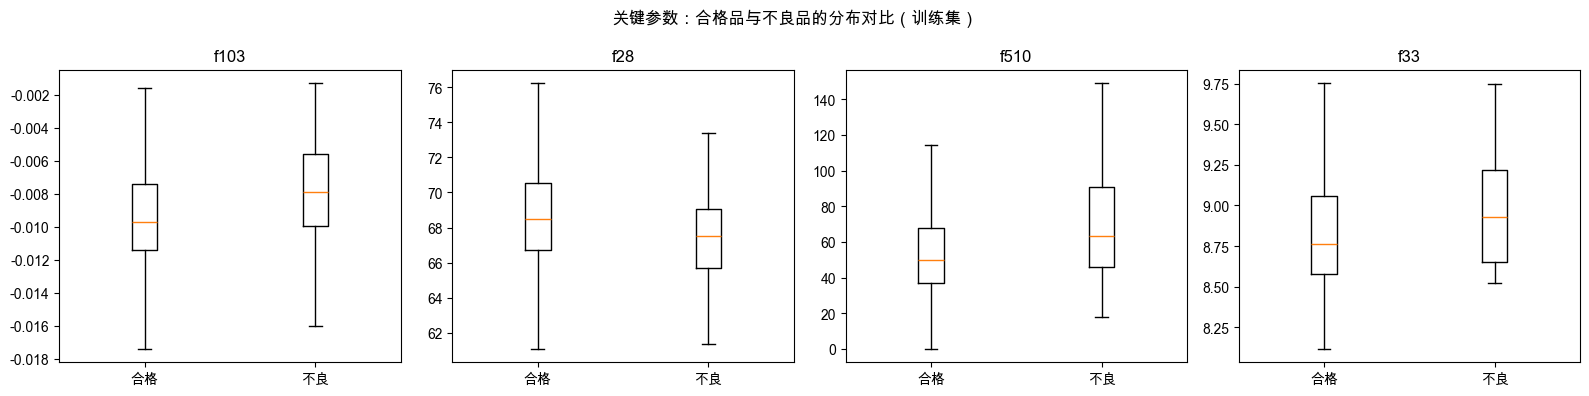

In [10]:
#画出最关键的4个参数
candidates = top[top["方向一致"] & top["RF重要性排名"].notna()].head(4)["feature"].tolist()
print("候选关键参数:", candidates)

fig, axes = plt.subplots(1, len(candidates), figsize=(4 * len(candidates), 4))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, candidates):
    data = [X_train.loc[y_train == 0, c], X_train.loc[y_train == 1, c]]
    ax.boxplot(data, labels=["合格", "不良"], showfliers=False)
    ax.set_title(c)
plt.suptitle("关键参数：合格品与不良品的分布对比（训练集）")
plt.tight_layout()
plt.show()

In [11]:
#导出Power BI所需的数据
import os
os.makedirs("dashboard", exist_ok=True)

# 重新读取原始数据（看板展示的是未经填补的真实读数）
raw = pd.read_csv("raw/secom.data", sep=" ", header=None)
raw.columns = [f"f{i}" for i in range(raw.shape[1])]
lab = pd.read_csv("raw/secom_labels.data", sep=" ", header=None, names=["label", "timestamp"])
lab["timestamp"] = pd.to_datetime(lab["timestamp"], dayfirst=True)

full = pd.concat([lab, raw], axis=1).sort_values("timestamp").reset_index(drop=True)
full["unit_id"] = np.arange(1, len(full) + 1)
full["fail"] = (full["label"] == 1).astype(int)
full["period"] = np.where(full.index < len(X_train), "Train", "Test")
# 风险分数：训练期用交叉验证的预测（模型没见过），测试期用最终模型的预测
full["risk_score"] = np.concatenate([oof_proba, test_proba])
full["risk_rank_pct"] = full.groupby("period")["risk_score"].rank(pct=True, ascending=False)

# 表 1：每个产品一行
units = full[["unit_id", "timestamp", "fail", "period", "risk_score", "risk_rank_pct"]]
units.to_csv("dashboard/units.csv", index=False)

# 表 2：关键参数的读数 + 控制限（控制限用训练期合格品计算：均值 ± 3 倍标准差）
key_params = {"f103": "Tier 1", "f510": "Tier 1", "f129": "Tier 2", "f21": "Tier 2", "f28": "Tier 2"}
train_pass = full[(full["period"] == "Train") & (full["fail"] == 0)]
limits = pd.DataFrame({
    "param": list(key_params),
    "tier": list(key_params.values()),
    "center": [train_pass[p].mean() for p in key_params],
    "sigma": [train_pass[p].std() for p in key_params],
})
limits["UCL"] = limits["center"] + 3 * limits["sigma"]
limits["LCL"] = limits["center"] - 3 * limits["sigma"]

params_long = (full.melt(id_vars=["unit_id", "timestamp", "fail", "period"],
                         value_vars=list(key_params), var_name="param", value_name="value")
                   .dropna(subset=["value"])
                   .merge(limits[["param", "tier", "center", "UCL", "LCL"]], on="param"))
params_long["out_of_limit"] = ((params_long["value"] > params_long["UCL"]) |
                               (params_long["value"] < params_long["LCL"])).astype(int)
params_long.to_csv("dashboard/param_readings.csv", index=False)

print("units.csv:", units.shape)
print("param_readings.csv:", params_long.shape)
limits.round(4)

units.csv: (1567, 6)
param_readings.csv: (7818, 11)


,param,tier,center,sigma,UCL,LCL
0,f103,Tier 1,-0.0094,0.0032,0.0001,-0.0189
1,f510,Tier 1,59.0030,40.1078,179.3263,-61.3203
2,f129,Tier 2,-0.5342,1.2471,3.2072,-4.2756
3,f21,Tier 2,-5687.6062,665.2688,-3691.7999,-7683.4125
4,f28,Tier 2,68.7354,3.3750,78.8603,58.6104


In [12]:
#修正控制限，并整理成一个Excel文件
# ① 修正：训练期没有负值的参数，下控制限不低于 0
for p in key_params:
    if full.loc[full["period"] == "Train", p].min() >= 0:
        limits.loc[limits["param"] == p, "LCL"] = limits.loc[limits["param"] == p, "LCL"].clip(lower=0)

# ② 重新生成参数读数表
params_long = (full.melt(id_vars=["unit_id", "timestamp", "fail", "period"],
                         value_vars=list(key_params), var_name="param", value_name="value")
                   .dropna(subset=["value"])
                   .merge(limits[["param", "tier", "center", "UCL", "LCL"]], on="param"))
params_long["out_of_limit"] = ((params_long["value"] > params_long["UCL"]) |
                               (params_long["value"] < params_long["LCL"])).astype(int)

# ③ 给产品表加上周和月，方便做趋势图
units = units.copy()
units["week_start"] = units["timestamp"].dt.to_period("W").dt.start_time
units["month"] = units["timestamp"].dt.strftime("%Y-%m")

# ④ 两张表写进同一个 Excel 文件
with pd.ExcelWriter("dashboard/secom_dashboard_data.xlsx") as writer:
    units.to_excel(writer, sheet_name="units", index=False)
    params_long.to_excel(writer, sheet_name="param_readings", index=False)

print("已保存 dashboard/secom_dashboard_data.xlsx")
print("超出控制限的读数数量：")
print(params_long.groupby("param")["out_of_limit"].sum())
limits.round(4)

已保存 dashboard/secom_dashboard_data.xlsx
超出控制限的读数数量：
param
f103     6
f129     0
f21     24
f28      0
f510    26
Name: out_of_limit, dtype: int64


,param,tier,center,sigma,UCL,LCL
0,f103,Tier 1,-0.0094,0.0032,0.0001,-0.0189
1,f510,Tier 1,59.0030,40.1078,179.3263,0.0000
2,f129,Tier 2,-0.5342,1.2471,3.2072,-4.2756
3,f21,Tier 2,-5687.6062,665.2688,-3691.7999,-7683.4125
4,f28,Tier 2,68.7354,3.3750,78.8603,58.6104
